In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_jujuy = pd.read_excel('../data/raw/Base Jujuy Consolidada Fer .xlsx',sheet_name='Base_Consolidada',header=1)

In [3]:
df_chubut = pd.read_excel('../data/processed/base chubut.xlsx')

In [3]:
df = pd.read_excel('../data/processed/eventos_chubut_jujuy.xlsx')

## Tipo de acción

**Definición de booleanos:**

Dado que los esquemas de codificación difieren entre Chubut y Jujuy, se construyeron booleanos que indican si el evento incluyó cada tipo de acción, sin importar la categoría original.

| Booleano | Chubut | Jujuy |
|---|---|---|
| tiene_marcha | Marcha, Manifestación, Caravana | Marcha + Mixta con marcha + Otra con marcha |
| tiene_corte | Corte | Corte |
| tiene_paro | Paro | Otra con paro + Mixta con paro |
| tiene_acto | Acto, Asamblea | Otra con asamblea + Acampe |
| tiene_escrache | Escrache | — |
| tiene_destrozos | Destrozos | — |
| tiene_toma | Toma de edificio | — |

Los porcentajes no suman 100% porque un evento puede incluir más de un tipo de acción.

In [4]:
print("Primeros episodios:")
df_jujuy.head()

Primeros episodios:


,ID,Localidad,Localidad_detalle,Actores participantes,Demanda principal,Tipo de acción,Tipo de acción_detalle,Disrupción,Escala,Intensidad,...,Heridos,Detenciones,Judicialización,Coord. Interinst.,Canales Inform.,Amenaza Política,Resultado,Fuente,Observaciones,Notas_estandarizacion
0,2023060301,San Salvador de Jujuy,San Salvador de Jujuy,Partidos políticos/Multisectorial de mujere/Co...,"respeto de los derechos de las mujeres, emerge...",Marcha,Marcha,0.0,Alta,Media,...,99.0,99.0,99.0,99.0,99.0,99.0,0.0,El Tribuno,https://eltribunodejujuy.com/nota/2023-6-3-1-0...,NaN
1,2023060302,Libertador General San Martín,Libertador General San Martín (Ingenio Ledesma...,Sindicato de Obreros y Empleados del Azúcar de...,Recomposición salarial: piden $280.000 para la...,Otra,Asamblea sindical + emplazamiento a la empresa...,0.0,Media,Sin datos,...,99.0,99.0,99.0,99.0,99.0,0.0,0.0,El Tribuno,https://eltribunodejujuy.com/nota/2023-6-3-1-0...,NaN
2,2023060501,San Salvador de Jujuy,San Salvador de Jujuy (frente a Legislatura/Co...,"Gremios de trabajadores estatales, CTA",Rechazo al articulo de la reforma constitucion...,Otra,Medidas de fuerza de gremios estatales y la CT...,0.0,Sin datos,Sin datos,...,99.0,99.0,99.0,99.0,99.0,1.0,0.0,El Tribuno,https://eltribunodejujuy.com/nota/2023-6-5-1-0...,Codificado a partir de fila pendiente (URL: t...
3,2023060601,Varias localidades,"Localidades principales Jujuy: San Pedro, Libe...","Docentes/Gremios | docentes, gremios",Salarial | mejoras salariales,Mixta,Movilización Mixta,0.0,Alta,Media,...,99.0,99.0,99.0,99.0,99.0,99.0,0.0,El Tribuno,En escala de movilización puse alta porque men...,NaN
4,2023060602,Varias localidades,San Salvador de Jujuy+otras localidades,"Docentes/Gremios | docentes, gremios",Salarial | mejoras salariales,Otra,paro por tiempo indefinido,1.0,Alta,Alta,...,99.0,99.0,99.0,99.0,99.0,99.0,0.0,El Tribuno,Disrupción si: porque es paro por tiempo indef...,NaN


In [5]:
print("\Columnas disponibles:")
df_jujuy.columns.tolist()

\Columnas disponibles:


<>:1: SyntaxWarning: invalid escape sequence '\C'
<>:1: SyntaxWarning: invalid escape sequence '\C'
C:\Users\Federico\AppData\Local\Temp\ipykernel_26688\2009912723.py:1: SyntaxWarning: invalid escape sequence '\C'
  print("\Columnas disponibles:")


['ID',
 'Localidad',
 'Localidad_detalle',
 'Actores participantes',
 'Demanda principal',
 'Tipo de acción',
 'Tipo de acción_detalle',
 'Disrupción',
 'Escala',
 'Intensidad',
 'Respuesta estatal',
 'Tipo Int. Estatal',
 'Presencia Policial',
 'Otros datos',
 'Uso Fuerza',
 'Heridos',
 'Detenciones',
 'Judicialización',
 'Coord. Interinst.',
 'Canales Inform.',
 'Amenaza Política',
 'Resultado',
 'Fuente',
 'Observaciones',
 'Notas_estandarizacion']

In [6]:
print("="*50)
print("📊 INFORMACIÓN GENERAL DE LA BASE")
print("="*50)
print(f"Total de episodios: {len(df_jujuy)}")
print(f"Columnas: {len(df_jujuy.columns)}")
print(f"Rango de fechas: ID desde {df_jujuy['ID'].min()} hasta {df_jujuy['ID'].max()}")

📊 INFORMACIÓN GENERAL DE LA BASE
Total de episodios: 66
Columnas: 25
Rango de fechas: ID desde 20230722 hasta 2023081001


In [30]:
print("\n" + "="*50)
print("📋 TIPOS DE ACCIÓN")
print("="*50)
print(df_jujuy['Tipo de acción'].value_counts())

print("\n" + "="*50)
print("📋 TIPOS DE ACCIÓN")
print("="*50)
print(df_chubut['tipo_accion'].value_counts())


📋 TIPOS DE ACCIÓN
Tipo de acción
Marcha    30
Corte     14
Mixta     12
Otra       9
Acampe     1
Name: count, dtype: int64

📋 TIPOS DE ACCIÓN
tipo_accion
Marcha                    30
Manifestación             23
Corte                     13
Paro                      10
Acto                      10
No especificado            9
Otra                       5
Destrozos                  5
Mixta                      4
Escrache                   4
Toma de edificio           3
Asamblea                   3
Caravana                   1
Difusión de comunicado     1
Name: count, dtype: int64



📋 TIPOS DE ACCIÓN


KeyError: 'Tipo de acción'

In [8]:
print("\n" + "="*50)
print("📊 ESCALA DE MOVILIZACIÓN")
print("="*50)
print(df_jujuy['Escala'].value_counts())


📊 ESCALA DE MOVILIZACIÓN
Escala
Alta         36
Media        19
Baja          7
Sin datos     2
Name: count, dtype: int64


In [9]:
print("\n" + "="*50)
print("🔥 INTENSIDAD")
print("="*50)
print(df_jujuy['Intensidad'].value_counts())


🔥 INTENSIDAD
Intensidad
Alta         31
Media        24
Baja          5
Sin datos     3
Muy Alta      2
Name: count, dtype: int64


In [10]:
print("\n" + "="*50)
print("🚨 TIPO DE INTERVENCIÓN ESTATAL")
print("="*50)
print("Códigos: 0=ausencia, 1=monitoreo, 2=contención, 3=disuasión, 4=represión")
print(df_jujuy['Tipo Int. Estatal'].value_counts().sort_index())



🚨 TIPO DE INTERVENCIÓN ESTATAL
Códigos: 0=ausencia, 1=monitoreo, 2=contención, 3=disuasión, 4=represión
Tipo Int. Estatal
0.0     33
1.0      9
2.0      4
3.0      2
4.0      5
99.0    12
Name: count, dtype: int64


In [11]:
print("\n" + "="*50)
print("📍 TOP 10 LOCALIDADES CON MÁS EPISODIOS")
print("="*50)
print(df_jujuy['Localidad'].value_counts().head(10))


📍 TOP 10 LOCALIDADES CON MÁS EPISODIOS
Localidad
San Salvador de Jujuy            34
Varias localidades               19
Libertador General San Martín     2
Tilcara                           2
Abra Pampa                        1
Purmamarca                        1
San Pedro de Jujuy                1
Ruta (sin localidad puntual)      1
Sin datos                         1
Finca El Pongo                    1
Name: count, dtype: int64


In [12]:
print("\n" + "="*50)
print("🔀 TIPO DE ACCIÓN vs INTERVENCIÓN ESTATAL")
print("="*50)
print(pd.crosstab(df_jujuy['Tipo de acción'], df_jujuy['Tipo Int. Estatal']))


🔀 TIPO DE ACCIÓN vs INTERVENCIÓN ESTATAL
Tipo Int. Estatal  0.0   1.0   2.0   3.0   4.0   99.0
Tipo de acción                                       
Acampe                0     0     1     0     0     0
Corte                 2     4     0     2     4     1
Marcha               20     1     0     0     1     8
Mixta                 6     4     1     0     0     1
Otra                  5     0     2     0     0     2


In [13]:
print("\n" + "="*50)
print("🔥 INTENSIDAD vs INTERVENCIÓN ESTATAL")
print("="*50)
print(pd.crosstab(df_jujuy['Intensidad'], df_jujuy['Tipo Int. Estatal']))


🔥 INTENSIDAD vs INTERVENCIÓN ESTATAL
Tipo Int. Estatal  0.0   1.0   2.0   3.0   4.0   99.0
Intensidad                                           
Alta                 13     5     1     1     3     8
Baja                  4     0     0     0     0     1
Media                14     3     2     1     1     3
Muy Alta              0     1     0     0     1     0
Sin datos             2     0     1     0     0     0


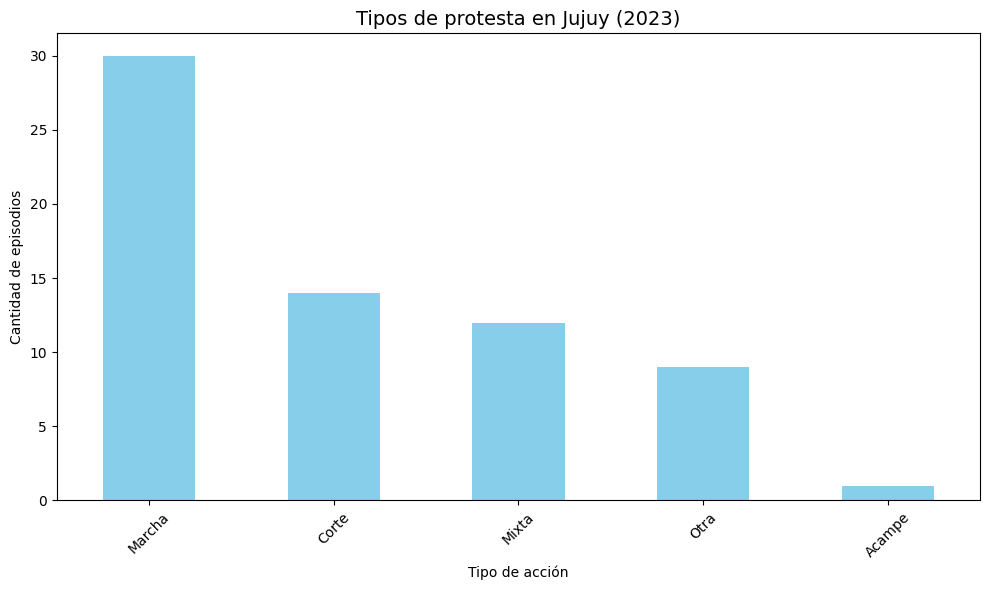

In [14]:
plt.figure(figsize=(10,6))
df_jujuy['Tipo de acción'].value_counts().plot(kind='bar', color='skyblue')
plt.title('Tipos de protesta en Jujuy (2023)', fontsize=14)
plt.xlabel('Tipo de acción')
plt.ylabel('Cantidad de episodios')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

<Figure size 1000x600 with 0 Axes>

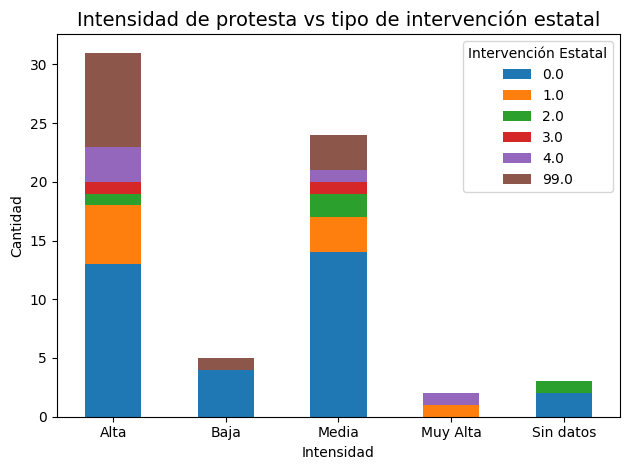

In [15]:
plt.figure(figsize=(10,6))
pd.crosstab(df_jujuy['Intensidad'], df_jujuy['Tipo Int. Estatal']).plot(kind='bar', stacked=True)
plt.title('Intensidad de protesta vs tipo de intervención estatal', fontsize=14)
plt.xlabel('Intensidad')
plt.ylabel('Cantidad')
plt.legend(title='Intervención Estatal')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [16]:
interv_map = {
    0.0: 'Sin intervención',
    1.0: 'Monitoreo',
    2.0: 'Contención',
    3.0: 'Disuasión',
    4.0: 'Represión',
    99.0: 'Sin datos'
}
df_jujuy['Intervención'] = df_jujuy['Tipo Int. Estatal'].map(interv_map)

In [17]:
df_filtrado = df_jujuy[df_jujuy['Tipo Int. Estatal'] != 99.0]

In [18]:
cruz = pd.crosstab(df_filtrado['Tipo de acción'], df_filtrado['Intervención'])

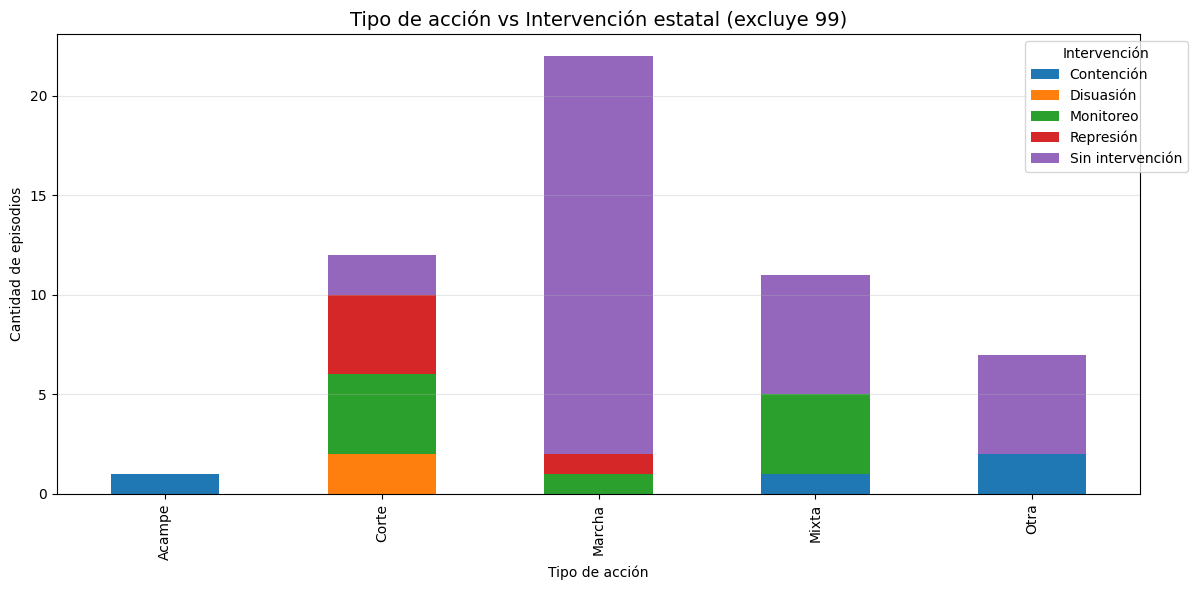

In [19]:
fig, ax = plt.subplots(figsize=(12, 6))
cruz.plot(kind='bar', ax=ax, stacked=True)
ax.set_title('Tipo de acción vs Intervención estatal (excluye 99)', fontsize=14)
ax.set_xlabel('Tipo de acción')
ax.set_ylabel('Cantidad de episodios')
ax.legend(title='Intervención', bbox_to_anchor=(1.05, 1))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [20]:
df_jujuy['ID_str'] = df_jujuy['ID'].astype(str)
df_jujuy['dia'] = df_jujuy['ID_str'].str[6:8].astype(float)  # Día del mes
df_jujuy['mes'] = df_jujuy['ID_str'].str[4:6].astype(float)  # Mes
df_jujuy['fecha'] = pd.to_datetime('2023-' + df_jujuy['mes'].astype(int).astype(str) + '-' + df_jujuy['dia'].astype(int).astype(str))

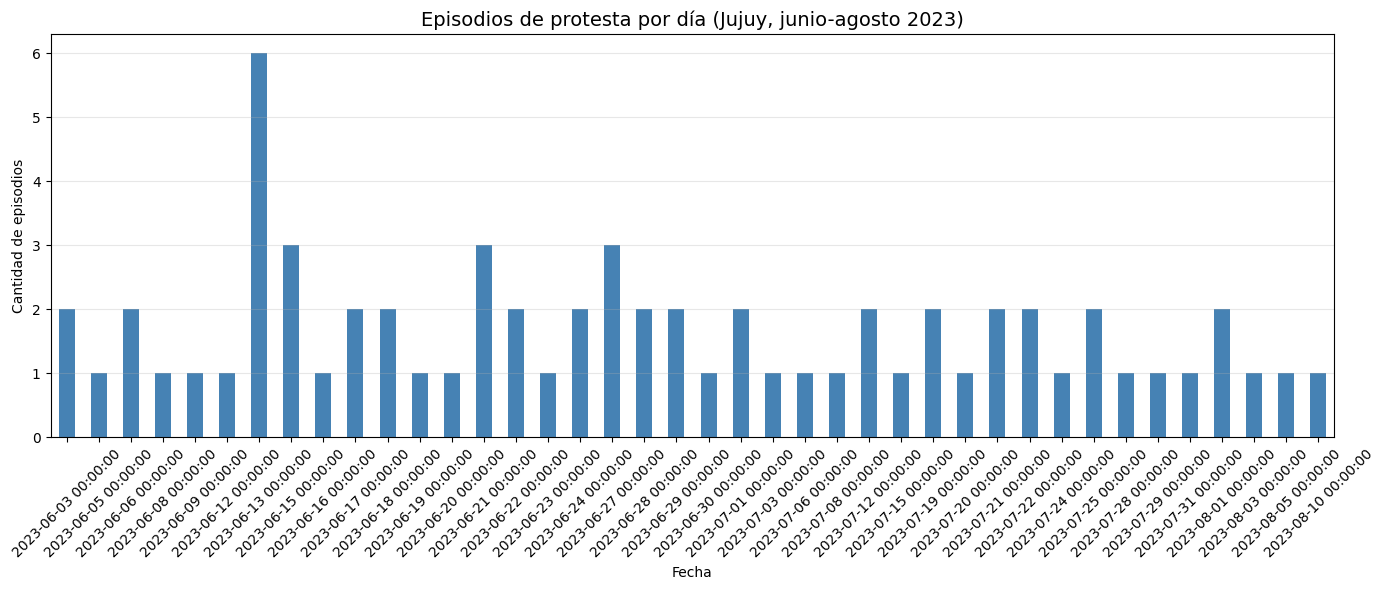

In [21]:
protestas_por_dia = df_jujuy.groupby('fecha').size()

fig, ax = plt.subplots(figsize=(14, 6))
protestas_por_dia.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Episodios de protesta por día (Jujuy, junio-agosto 2023)', fontsize=14)
ax.set_xlabel('Fecha')
ax.set_ylabel('Cantidad de episodios')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

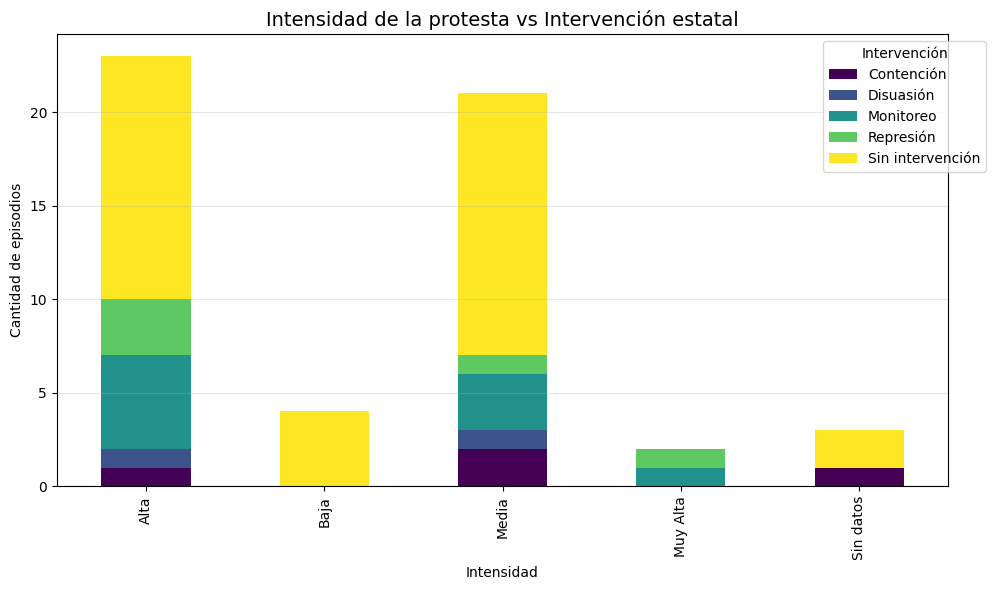

In [22]:
df_filtrado2 = df_jujuy[df_jujuy['Tipo Int. Estatal'] != 99.0]
tabla_int = pd.crosstab(df_filtrado2['Intensidad'], df_filtrado2['Intervención'])

fig, ax = plt.subplots(figsize=(10, 6))
tabla_int.plot(kind='bar', ax=ax, stacked=True, colormap='viridis')
ax.set_title('Intensidad de la protesta vs Intervención estatal', fontsize=14)
ax.set_xlabel('Intensidad')
ax.set_ylabel('Cantidad de episodios')
ax.legend(title='Intervención', bbox_to_anchor=(1.05, 1))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

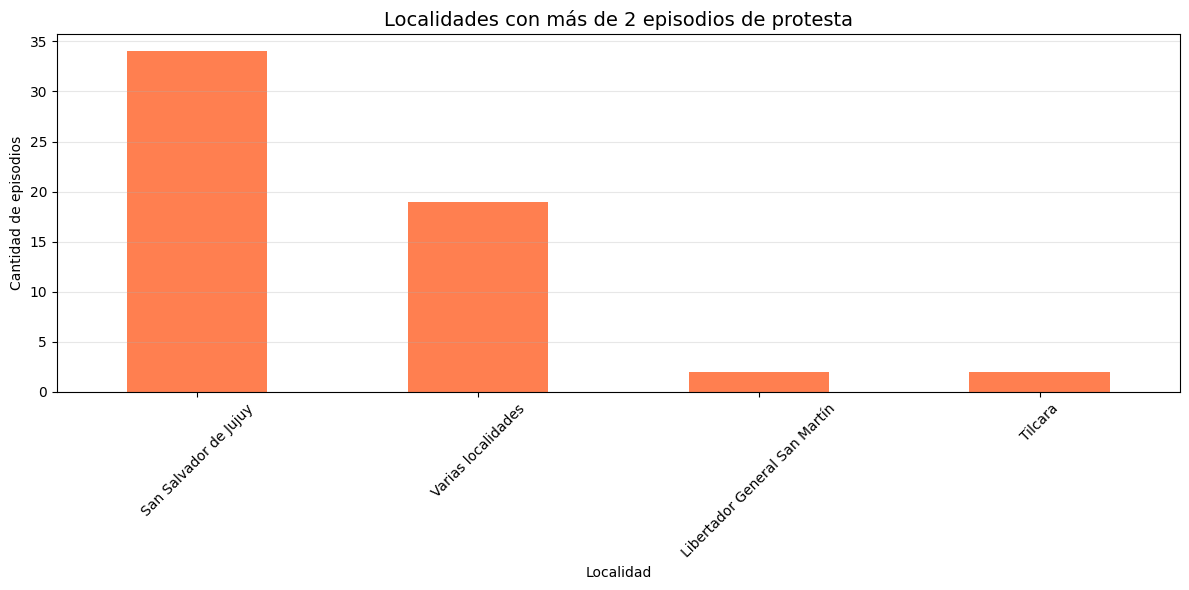

In [23]:
locales = df_jujuy['Localidad'].value_counts()
locales_filt = locales[locales >= 2]

fig, ax = plt.subplots(figsize=(12, 6))
locales_filt.plot(kind='bar', ax=ax, color='coral')
ax.set_title('Localidades con más de 2 episodios de protesta', fontsize=14)
ax.set_xlabel('Localidad')
ax.set_ylabel('Cantidad de episodios')
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

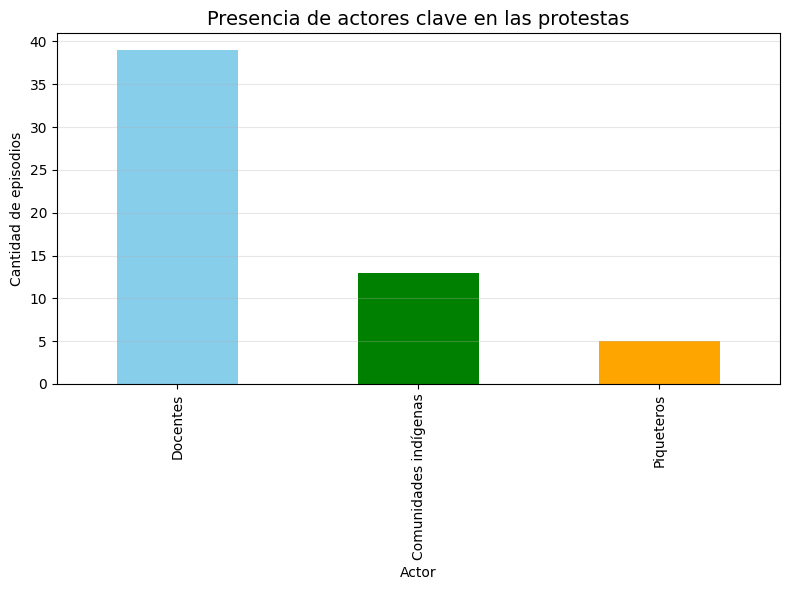

In [24]:
df_jujuy['menciona_docente'] = df_jujuy['Actores participantes'].str.contains('docente|Docente', na=False)
df_jujuy['menciona_indigena'] = df_jujuy['Actores participantes'].str.contains('indígena|originaria|comunidad', na=False)
df_jujuy['menciona_piquetero'] = df_jujuy['Actores participantes'].str.contains('piquetero|Piquetero', na=False)

actores = {
    'Docentes': df_jujuy['menciona_docente'].sum(),
    'Comunidades indígenas': df_jujuy['menciona_indigena'].sum(),
    'Piqueteros': df_jujuy['menciona_piquetero'].sum()
}
actores_df = pd.DataFrame(list(actores.items()), columns=['Actor', 'Cantidad'])

fig, ax = plt.subplots(figsize=(8, 6))
actores_df.plot(kind='bar', x='Actor', y='Cantidad', ax=ax, legend=False, color=['skyblue', 'green', 'orange'])
ax.set_title('Presencia de actores clave en las protestas', fontsize=14)
ax.set_xlabel('Actor')
ax.set_ylabel('Cantidad de episodios')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()